# Used Car Price Prediction — Part 2: Feature Engineering & Model Training

In [13]:
import os, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, root_mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
warnings.filterwarnings('ignore', message='X does not have valid feature names')
plt.style.use('seaborn-v0_8-whitegrid')

REFERENCE_YEAR = 2026
RANDOM_STATE = 42

## Load data and build features
Exact duplicate rows are removed first (a deterministic clean-up, not a learned transformation). `Car_Age = 2026 − Year`; `Year` and `Car_Name` are dropped.

In [2]:
df = pd.read_csv('../data/car_data.csv')
print('Raw shape:', df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print('After dropping duplicates:', df.shape)

df['Car_Age'] = REFERENCE_YEAR - df['Year']
cat_features = ['Fuel_Type', 'Seller_Type', 'Transmission']
num_features = ['Present_Price', 'Kms_Driven', 'Car_Age', 'Owner']
FEATURES = num_features + cat_features

X = df[FEATURES]
y = df['Selling_Price']

Raw shape: (301, 9)
After dropping duplicates: (299, 9)


## 80/20 train / held-out test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (239, 7)  Test: (60, 7)


## Outlier rule (decided during EDA, before any modelling)
Rule: **drop training rows with `Kms_Driven > 300,000`**. The EDA showed a single 500,000 km listing, more than double the next-highest value, which looks like a data-entry error. The rule is applied to the training split only; the test set is left untouched so the final evaluation reflects real incoming data. High `Selling_Price` values are genuine luxury cars and are kept.

In [4]:
mask = X_train['Kms_Driven'] <= 300_000
print('Training rows removed by outlier rule:', (~mask).sum())
X_train, y_train = X_train[mask], y_train[mask]
print('Final training shape:', X_train.shape)

Training rows removed by outlier rule: 0
Final training shape: (239, 7)


## Preprocessing inside a Pipeline
One-hot encoding for nominal features; numeric scaling only for the linear models.

In [5]:
def make_preprocessor(scale_numeric=False):
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
        ('num', StandardScaler() if scale_numeric else 'passthrough', num_features)
    ])

def make_pipeline(model, scale_numeric=False):
    return Pipeline([('preprocessor', make_preprocessor(scale_numeric)), ('model', model)])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'r2': 'r2', 'rmse': 'neg_root_mean_squared_error'}

## Hyperparameter tuning (5-fold CV on the training split only)
Every grid search uses the same `cv` folds. The test set is not touched here.

In [14]:
candidates = {
    'Linear Regression': (LinearRegression(), True, {}),
    'Ridge Regression': (Ridge(), True, {'model__alpha': [0.1, 1.0, 10.0]}),
    'Random Forest': (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), False,
                      {'model__n_estimators': [100, 200]}),
    'XGBoost': (XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1), False,
                {'model__n_estimators': [100, 300], 'model__learning_rate': [0.05, 0.1, 0.3], 'model__max_depth': [3, 6]}),
    'LightGBM': (LGBMRegressor(random_state=RANDOM_STATE, verbose=-1), False,
                 {'model__min_child_samples': [5, 10, 20], 'model__num_leaves': [15, 31]}),
}

# Default-parameter baselines for the boosted models (reported for reference)
for name in ['XGBoost', 'LightGBM']:
    est, scale, _ = candidates[name]
    s = cross_validate(make_pipeline(est, scale), X_train, y_train, cv=cv, scoring=scoring)
    print(f"{name} (default params)  CV R2 = {s['test_r2'].mean():.4f}   CV RMSE = {-s['test_rmse'].mean():.4f}")

best_params = {}
for name, (est, scale, grid) in candidates.items():
    if grid:
        gs = GridSearchCV(make_pipeline(est, scale), grid, cv=cv, scoring='r2', n_jobs=-1)
        gs.fit(X_train, y_train)
        best_params[name] = gs.best_params_
        print(f"{name:18s} best params: {gs.best_params_}  (CV R2 {gs.best_score_:.4f})")
    else:
        best_params[name] = {}

XGBoost (default params)  CV R2 = 0.8847   CV RMSE = 1.5916
LightGBM (default params)  CV R2 = 0.8163   CV RMSE = 2.0932
Ridge Regression   best params: {'model__alpha': 10.0}  (CV R2 0.8890)
Random Forest      best params: {'model__n_estimators': 200}  (CV R2 0.8939)
XGBoost            best params: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 300}  (CV R2 0.9046)
LightGBM           best params: {'model__min_child_samples': 5, 'model__num_leaves': 15}  (CV R2 0.8952)


## Model comparison (cross-validation of each tuned pipeline)

In [15]:
results, tuned = [], {}
for name, (est, scale, _) in candidates.items():
    pipe = make_pipeline(est, scale).set_params(**best_params[name])
    tuned[name] = (pipe, scale)
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    results.append({'Model': name,
                    'Train R2 (CV)': s['train_r2'].mean(),
                    'CV R2': s['test_r2'].mean(),
                    'CV RMSE': -s['test_rmse'].mean(),
                    'CV R2 std': s['test_r2'].std()})

cv_table = pd.DataFrame(results).sort_values('CV R2', ascending=False).reset_index(drop=True)
cv_table.round(4)

,Model,Train R2 (CV),CV R2,CV RMSE,CV R2 std
0,XGBoost,0.9972,0.9046,1.4462,0.1076
1,LightGBM,0.9871,0.8952,1.5430,0.0694
2,Random Forest,0.9830,0.8939,1.5140,0.0847
3,Ridge Regression,0.9047,0.8890,1.6069,0.0266
4,Linear Regression,0.9069,0.8850,1.6451,0.0289


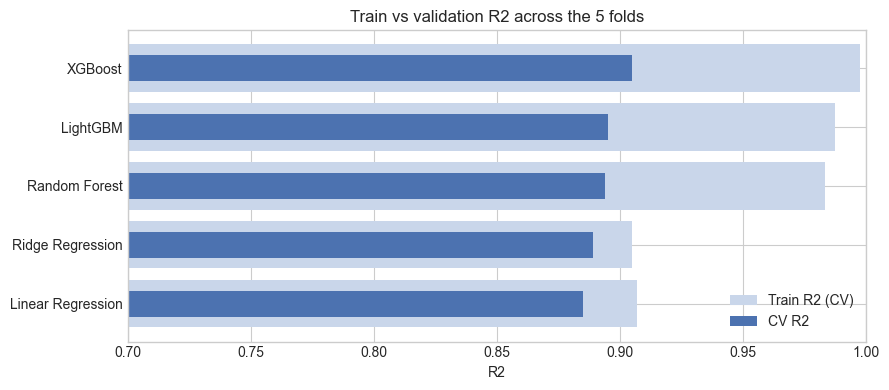

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
t = cv_table.sort_values('CV R2')
ax.barh(t['Model'], t['Train R2 (CV)'], color='#C9D6EA', label='Train R2 (CV)')
ax.barh(t['Model'], t['CV R2'], height=0.45, color='#4C72B0', label='CV R2')
ax.set_xlim(0.7, 1.0); ax.set_xlabel('R2'); ax.legend(loc='lower right')
ax.set_title('Train vs validation R2 across the 5 folds')
plt.tight_layout(); plt.show()

## Select the best model by CV R2, then evaluate once on the held-out test set

In [9]:
best_name = cv_table.loc[0, 'Model']
pipeline, selected_scale_numeric = tuned[best_name]
print('Selected model:', best_name, best_params[best_name])

pipeline.fit(X_train, y_train)          # fit preprocessing + model together on the full training split
y_pred = pipeline.predict(X_test)
test_r2 = r2_score(y_test, y_pred)
test_rmse = root_mean_squared_error(y_test, y_pred)
print(f'Final Test R2   : {test_r2:.4f}')
print(f'Final Test RMSE : {test_rmse:.4f} lakhs')

Selected model: XGBoost {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 300}
Final Test R2   : 0.8628
Final Test RMSE : 1.8804 lakhs


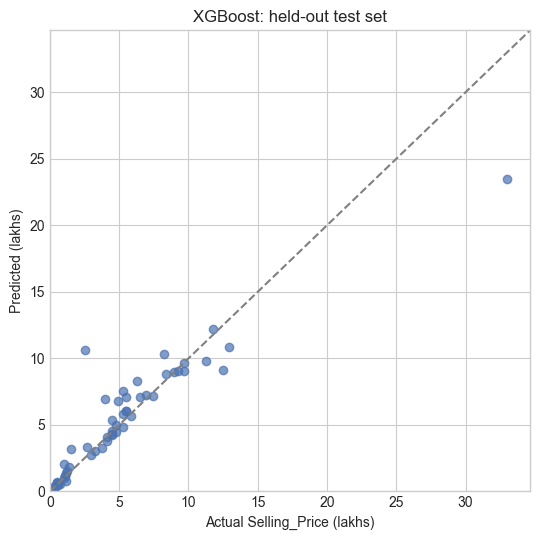

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_test, y_pred, alpha=.7, color='#4C72B0')
lim = [0, max(y_test.max(), y_pred.max()) * 1.05]
ax.plot(lim, lim, '--', color='grey')
ax.set(xlim=lim, ylim=lim, xlabel='Actual Selling_Price (lakhs)', ylabel='Predicted (lakhs)',
       title=f'{best_name}: held-out test set')
plt.tight_layout(); plt.show()

## Feature importance (matched to transformed feature names)

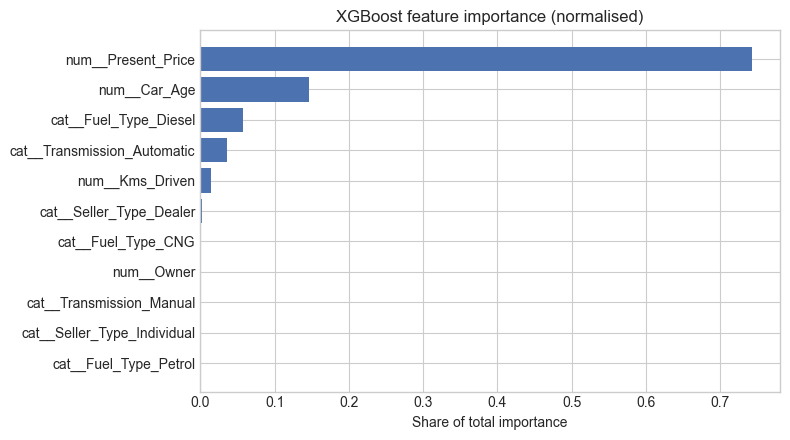

num__Present_Price             0.7434
num__Car_Age                   0.1461
cat__Fuel_Type_Diesel          0.0570
cat__Transmission_Automatic    0.0357
num__Kms_Driven                0.0142
cat__Seller_Type_Dealer        0.0029
cat__Fuel_Type_CNG             0.0006
num__Owner                     0.0001
cat__Transmission_Manual       0.0000
cat__Fuel_Type_Petrol          0.0000
cat__Seller_Type_Individual    0.0000
dtype: float32


In [11]:
model = pipeline.named_steps['model']
feat_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
if hasattr(model, 'feature_importances_'):
    imp = pd.Series(model.feature_importances_, index=feat_names)
    imp = imp / imp.sum()
    imp = imp.sort_values()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(imp.index, imp.values, color='#4C72B0')
    ax.set(title=f'{best_name} feature importance (normalised)', xlabel='Share of total importance')
    plt.tight_layout(); plt.show()
    print(imp.sort_values(ascending=False).round(4))
else:
    coefs = pd.Series(model.coef_, index=feat_names).sort_values()
    print(coefs)

## Save the fitted pipeline

In [12]:
os.makedirs('../models', exist_ok=True)
joblib.dump(pipeline, '../models/best_model.pkl')
cv_table.round(4).to_csv('../models/cv_results.csv', index=False)
pd.Series({'model': best_name, 'test_r2': round(test_r2, 4), 'test_rmse': round(test_rmse, 4)}).to_csv('../models/test_metrics.csv')

# sanity check: reload and predict
reloaded = joblib.load('../models/best_model.pkl')
assert np.allclose(reloaded.predict(X_test), y_pred)
print('Saved and verified models/best_model.pkl')
print('Car_Age range in training data:', X_train['Car_Age'].min(), '-', X_train['Car_Age'].max())
print('Present_Price range:', X_train['Present_Price'].min(), '-', X_train['Present_Price'].max())

Saved and verified models/best_model.pkl
Car_Age range in training data: 9 - 23
Present_Price range: 0.32 - 92.6


## Discussion

**Why XGBoost was selected.** Ranked by mean 5-fold CV R², tuned XGBoost (`n_estimators=300, learning_rate=0.05, max_depth=3`) scored highest (CV R² ≈ 0.905, CV RMSE ≈ 1.45 lakhs), ahead of LightGBM, Random Forest, Ridge and Linear Regression. Price depends on `Present_Price` in a non-linear way that interacts with age (older cars keep a smaller *fraction* of their showroom price, as seen in the EDA), and fuel/transmission shift that curve. Gradient-boosted shallow trees capture these interactions; linear models can only add effects together. A small learning rate with shallow trees worked best on this small (239-row) training set. LightGBM needed `min_child_samples=5` to work well: its default (20) is too large for so few rows, which is why its default CV R² was only ≈ 0.82.

**Overfitting.** The tree models fit the training folds almost perfectly (train R² 0.98–0.997) while validation R² is ≈ 0.89–0.90, a gap of ~0.09. That is a real variance gap, expected on 239 rows, but validation performance is still the best of all models, so the extra flexibility pays off. The linear models show almost no gap (≈0.905 vs ≈0.885–0.889) but have higher bias. XGBoost's fold-to-fold CV R² standard deviation is also the largest (≈0.11), meaning results depend noticeably on which expensive cars fall into a fold.

**Held-out test result.** The pipeline was fitted on the full training split and evaluated once on the 60-row test set: **Test R² ≈ 0.863, Test RMSE ≈ 1.88 lakhs**. This is somewhat below CV, which fits the fold variability above. Most of the test error comes from two cars: a 33-lakh Fortuner (under-predicted, few training examples at that price) and a 20-year-old Camry with a high showroom price (over-predicted). With only 60 test rows, a couple of unusual cars move the score a lot.

**Link to the EDA.** Feature importance matches the EDA: `Present_Price` dominates (~74% of importance), followed by `Car_Age` (~15%), then Diesel and Automatic. `Kms_Driven`, `Owner` and `Seller_Type` contribute very little, consistent with their weak correlations. `Seller_Type` adds little once `Present_Price` is known, since individual sellers mainly list cheap vehicles. The pre-agreed outlier rule (`Kms_Driven > 300,000`) removed no training rows, because the single 500,000 km listing landed in the test split; it was left there untouched. The right-skewed target explains why errors concentrate on the few expensive cars.